In [6]:
from climada.hazard import TropCyclone, Centroids, TCTracks
from climada.entity.exposures import LitPop
from climada.engine import ImpactCalc, Impact

from climada.entity import Exposures
from climada.entity.impact_funcs import ImpactFuncSet, ImpactFunc, ImpfTropCyclone

import numpy as np


In [7]:
country = 'AUS'
m, n = 1, 1
res_arcsec = 300
fin_mode = 'pc'
ref_year = 2020


In [8]:
exp1 = LitPop.from_countries(country, res_arcsec, (m,n), fin_mode, reference_year = ref_year)
exp1.check()

exp = Exposures(exp1.gdf[exp1.geometry.x <= 155])
exp.check()

exp.gdf['impf_TC'] = 1


In [9]:
# # Define a standard Emanuel 2011-style curve
# imp_func = ImpactFunc()
# if_set = ImpactFuncSet()

# # It is crucial that these IDs match your exposure data!
# imp_func.id = 1 
# imp_func.haz_type = 'TC'
# imp_func.intensity_unit = 'm/s'

# # Default sigmoid-style curve logic
# imp_func.intensity = np.linspace(0, 100, 50)
# v_half = 50 # Wind speed where 50% damage occurs
# imp_func.mdd = imp_func.intensity**3 / (v_half**3 + imp_func.intensity**3)
# imp_func.paa = np.ones(len(imp_func.intensity))

# if_set.append(imp_func)

if_tc = ImpfTropCyclone.from_emanuel_usa()
if_set = ImpactFuncSet([if_tc])
if_set.check()


In [10]:
from pathlib import Path

HAZ_DIR = Path("../hazard")

def calc_aggregate_annual_loss_emp_dist(folder, exp, if_set, haz_dir=HAZ_DIR, pattern="*.hdf5"):
    year_dir = Path(haz_dir).joinpath(folder)
    files = sorted(year_dir.glob(pattern))

    if not files:
        raise ValueError(f"No hazard files found in {year_dir} matching '{pattern}'")

    annual_losses = []
    file_paths = []

    for i, f in enumerate(files, start=1):
        tc_hazard = TropCyclone.from_hdf5(f)

        # some saved hazard files carry a malformed (non-1D) `frequency`
        # array, which crashes CLIMADA's internal eai_exp computation even
        # though we only need at_event here (frequency doesn't affect
        # at_event) -- force it to a clean 1-D array before calling calc()
        tc_hazard.frequency = np.ones(tc_hazard.event_id.size)

        impact = ImpactCalc(exp, if_set, tc_hazard).impact(save_mat=False)

        annual_loss = impact.at_event.sum()
        annual_losses.append(annual_loss)
        file_paths.append(f)

        if i % 10 == 0 or i == len(files):
            print(f"[{folder}] processed {i}/{len(files)} files")

    return np.array(annual_losses), file_paths


In [13]:
annual_losses_storm, files_storm = calc_aggregate_annual_loss_emp_dist("STORM", exp, if_set)
annual_losses_iris, files_iris = calc_aggregate_annual_loss_emp_dist("IRIS", exp, if_set)
annual_losses_chaz, files_chaz = calc_aggregate_annual_loss_emp_dist("CHAZ", exp, if_set)
annual_losses_IBTrACS_p, files_IBTrACS_p = calc_aggregate_annual_loss_emp_dist("Counterfactuals/IBTrACS_p/prob070", exp, if_set)
annual_losses_WNC_QM, files_WNC_QM = calc_aggregate_annual_loss_emp_dist("Counterfactuals/Mini-TC-QM/prob070", exp, if_set)
annual_losses_IBTrACS, files_IBTrACS = calc_aggregate_annual_loss_emp_dist("IBTrACS_AU", exp, if_set)
annual_losses_MiniWNC, files_MiniWNC = calc_aggregate_annual_loss_emp_dist("Counterfactuals/Mini-TC/prob070", exp, if_set)


[Counterfactuals/Mini-TC/prob070] processed 10/8000 files
[Counterfactuals/Mini-TC/prob070] processed 20/8000 files
[Counterfactuals/Mini-TC/prob070] processed 30/8000 files
[Counterfactuals/Mini-TC/prob070] processed 40/8000 files
[Counterfactuals/Mini-TC/prob070] processed 50/8000 files
[Counterfactuals/Mini-TC/prob070] processed 60/8000 files
[Counterfactuals/Mini-TC/prob070] processed 70/8000 files
[Counterfactuals/Mini-TC/prob070] processed 80/8000 files
[Counterfactuals/Mini-TC/prob070] processed 90/8000 files
[Counterfactuals/Mini-TC/prob070] processed 100/8000 files
[Counterfactuals/Mini-TC/prob070] processed 110/8000 files
[Counterfactuals/Mini-TC/prob070] processed 120/8000 files
[Counterfactuals/Mini-TC/prob070] processed 130/8000 files
[Counterfactuals/Mini-TC/prob070] processed 140/8000 files
[Counterfactuals/Mini-TC/prob070] processed 150/8000 files
[Counterfactuals/Mini-TC/prob070] processed 160/8000 files
[Counterfactuals/Mini-TC/prob070] processed 170/8000 files
[Count

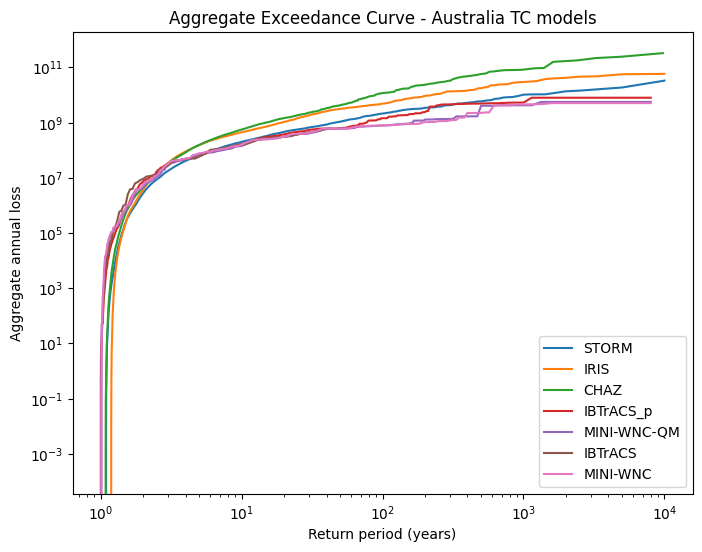

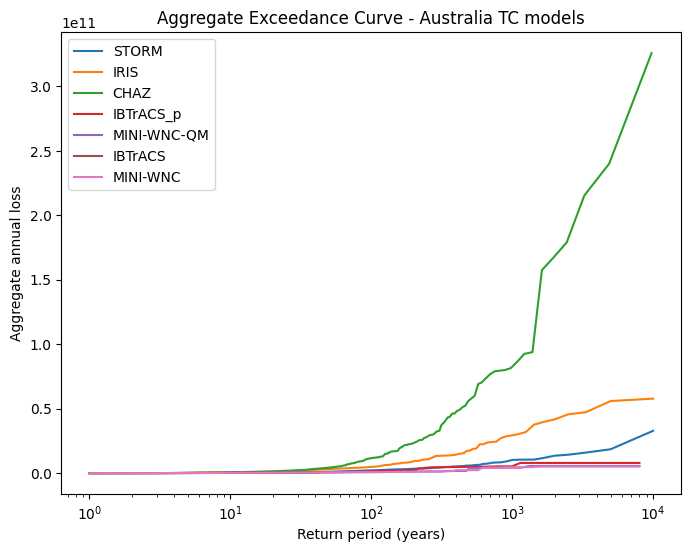

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results = {
    "STORM": (annual_losses_storm, files_storm),
    "IRIS": (annual_losses_iris, files_iris),
    "CHAZ": (annual_losses_chaz, files_chaz),
    "IBTrACS_p": (annual_losses_IBTrACS_p, files_IBTrACS_p),
    "MINI-WNC-QM": (annual_losses_WNC_QM, files_WNC_QM),
    "IBTrACS": (annual_losses_IBTrACS, files_IBTrACS),
    "MINI-WNC": (annual_losses_MiniWNC, files_MiniWNC),
}


def exceedance_curve(losses):
    """Empirical aggregate exceedance curve: sort losses descending, assign
    each one a return period via the standard (n+1)/rank plotting-position
    formula. Returns (return_period, sorted_loss), aligned by rank."""
    losses_sorted = np.sort(losses)[::-1]
    n = len(losses_sorted)
    rank = np.arange(1, n + 1)
    return_period = (n + 1) / rank
    return return_period, losses_sorted


def plot_exceedance(results, log_y=True):
    fig, ax = plt.subplots(figsize=(8, 6))
    for name, (losses, _) in results.items():
        rp, loss_sorted = exceedance_curve(losses)
        ax.plot(rp, loss_sorted, label=name)

    ax.set_xscale("log")
    if log_y:
        ax.set_yscale("log")
    ax.set_xlabel("Return period (years)")
    ax.set_ylabel("Aggregate annual loss")
    ax.set_title("Aggregate Exceedance Curve - Australia TC models")
    ax.legend()
    return fig, ax


fig, ax = plot_exceedance(results, log_y=True)
fig.savefig(RESULTS_DIR / "aggregate_exceedance_logy.png", dpi=150)

fig, ax = plot_exceedance(results, log_y=False)
fig.savefig(RESULTS_DIR / "aggregate_exceedance_liny.png", dpi=150)

plt.show()


In [15]:
import pandas as pd

def save_results_to_csv(results, out_path=RESULTS_DIR / "annual_losses_v2.csv"):
    rows = [
        {"model": model_name, "loss": loss, "file": str(f)}
        for model_name, (losses, files) in results.items()
        for loss, f in zip(losses, files)
    ]
    df = pd.DataFrame(rows, columns=["model", "loss", "file"])
    df.to_csv(out_path, index=False)
    print(f"Saved {len(df)} rows to {out_path}")
    return df


df_results = save_results_to_csv(results)


Saved 53791 rows to ..\results\annual_losses_v2.csv


In [16]:
df_results[df_results['model'] == 'MINI-WNC-QM']["loss"].value_counts().head(20)


Series([], Name: count, dtype: int64)